# A6 · How large must a RankMe opportunity be?

**Complete** · 5/5 classifiers · 60/60 independent trajectories

Each variant uses B3 with the A5 M0 health and action inputs. The event is an encoder update with **non-increasing reconstruction loss** and a RankMe increase strictly above the specified fraction of its seed’s calibration scale. T0 uses strict positivity. T4 reproduces A6's 10% target. All five classifiers use the same trees, training clips and balanced weighting rule. They use the same training-calibrated T4 probability cutoff. The reconstruction fallback and its meaningful loss threshold are shared.

Direct attainable gain is the sum of the largest feasible **raw RankMe increase** at each archived held-out state, with zero for states that offer none. The four horizons can share images and parent models. This sum describes recorded one-step opportunities. It cannot establish the gain along a single evolving model trajectory.

Classifier precision, recall and average precision (stepwise PR-AUC) are measured on the seven encoder-changing actions. State AP evaluates whether any action is feasible. Choice recall and precision assess whether the single selected action was feasible, with denominators of all opportunity states and all selected encoder updates respectively.

In [ ]:
import base64,gzip,io,json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score
from IPython.display import display,Markdown
name='MAE_A6_Minimum_RankMe_Gain.ipynb'
path=next(p for d in (Path.cwd(),*Path.cwd().parents) for p in (d/name,d/'project/cafl4ds/notebooks/selected/mae'/name) if p.exists())
meta=json.loads(path.read_bytes())['metadata']['threshold_sweep']
def unpack(k):
    with np.load(io.BytesIO(base64.b64decode(meta[k]))) as f:return dict(f)
truth=unpack('truth')
traces=json.loads(gzip.decompress(base64.b64decode(meta['traces'])))
LEVELS=dict(T0=0.,T1=.01,T2=.025,T3=.05,T4=.10)
scores={k:unpack(k) for k in LEVELS if k in meta}

In [ ]:
def metrics(truth, scorefile, threshold, horizon=None):
    take=np.ones(len(truth['h']),bool) if horizon is None else truth['h']==horizon
    y=truth['y'][take]
    enc=truth['enc']; denom=truth['scales'][take,1,None]
    good=(y[:,:,0]>=0)&(y[:,:,1]/denom>threshold)&enc
    available=good.any(1)
    best=np.where(good,y[:,:,1],0).max(1)
    result=dict(states=len(best),events=int(available.sum()),pct=100*available.mean(),
                clips=int(len(np.unique(truth['clip'][take][available]))),direct_sum=float(best.sum()))
    if scorefile is None:return result
    prob=scorefile['score'][take][:,enc]
    pos=good[:,enc]; predicted=prob>=scorefile['cutoff'].item()
    choice=scorefile['action'][take]
    successful=good[np.arange(len(choice)),choice]
    def rate(n,d):return n/d if d else None
    def ap(t,p):return float(average_precision_score(t.ravel(),p.ravel())) if t.any() else None
    return dict(result,precision=rate((predicted&pos).sum(),predicted.sum()),recall=rate((predicted&pos).sum(),pos.sum()),
                action_ap=ap(pos,prob),state_ap=ap(available,prob.max(1)),
                choice_recall=rate(successful.sum(),available.sum()),choice_precision=rate(successful.sum(),enc[choice].sum()))

def trajectories_plot(traces,h):
    fig,axs=plt.subplots(1,3,figsize=(13,3.8),layout='constrained')
    for name in LEVELS:
        rr=[r for r in traces if r['variant']==name and r['h']==h]
        if not rr:continue
        ranks=np.array([[r['initial_rank']]+[s['audit_rank'] for s in r['steps']] for r in rr])
        loss=np.array([[np.mean(r['cohort'][str(i)]) for i in range(0,129,16)] for r in rr])
        # Mean over trained images in each 16-decision interval. Skips do not enter this panel.
        trained=[]
        for i in range(0,128,16):
            vals=[s['x0_post'] for r in rr for s in r['steps'][i:i+16] if s['action']]
            trained.append(np.mean(vals) if vals else np.nan)
        axs[0].plot(ranks.mean(0),label=f"{name} ({len(rr)})")
        axs[1].plot(range(0,129,16),loss.mean(0),marker='.')
        axs[2].plot(range(16,129,16),trained,marker='.')
    for ax,title in zip(axs,['Independent audit RankMe','Fixed origin cohort loss','Post-update loss on trained x0']):
        ax.set(title=title,xlabel='Decision');ax.grid(axis='y',alpha=.2)
    axs[0].legend(fontsize=7);fig.suptitle(f'Learned B3/M0 control · H{h} · base LR 0.001')
    return fig

def endpoints(traces):
    lines=['| H | Variant | Seeds | Mean audit RankMe change | Mean cohort loss change | Selection-bank gains also positive on audit | Rank-first updates worsening reconstruction |',
           '|---|---|---:|---:|---:|---:|---:|']
    for h in (0,1,4,16):
        for name in LEVELS:
            runs=[r for r in traces if r['h']==h and r['variant']==name]
            if not runs:continue
            confirmed=positive=violations=calls=0
            for r in runs:
                prev_sel,prev_audit=r['initial_select_rank'],r['initial_rank']
                for s in r['steps']:
                    if s['select_rank']>prev_sel:
                        positive+=1
                        confirmed+=int(s['audit_rank']>prev_audit)
                    if s['stage']=='rank':
                        calls+=1
                        violations+=int(s['lookahead_gain']<0)
                    prev_sel,prev_audit=s['select_rank'],s['audit_rank']
            gain=np.mean([r['steps'][-1]['audit_rank']-r['initial_rank'] for r in runs])
            loss=np.mean([np.mean(r['cohort']['128'])-np.mean(r['cohort']['0']) for r in runs])
            lines.append(f'| {h} | {name} | {len(runs)} | {gain:+.4f} | {loss:+.5f} | {confirmed}/{positive} | {violations}/{calls} |')
    return '\n'.join(lines)


In [ ]:
def results_table(horizon=None):
    rows=['| Variant | Minimum | Feasible states | States (%) | Positive clips | Direct attainable gain | Precision | Recall | Action PR-AUC | State PR-AUC | Choice recall | Choice precision |','|'+'---|'*12]
    for name,t in LEVELS.items():
        v=metrics(truth,scores.get(name),t,horizon)
        nums=[v.get(k) for k in ('precision','recall','action_ap','state_ap','choice_recall','choice_precision')]
        vals=[name,f'{100*t:g}%',f"{v['events']}/{v['states']}",f"{v['pct']:.2f}",str(v['clips']),f"{v['direct_sum']:.4f}"]+[f'{n:.4f}' if n is not None else '—' for n in nums]
        rows.append('| '+' | '.join(vals)+' |')
    return '\n'.join(rows)
for horizon in (None,0,1,4,16):
    display(Markdown(('**All horizons**' if horizon is None else f'**H{horizon}**')+'\n\n'+results_table(horizon)))

**All horizons**

| Variant | Minimum | Feasible states | States (%) | Positive clips | Direct attainable gain | Precision | Recall | Action PR-AUC | State PR-AUC | Choice recall | Choice precision |
|---|---|---|---|---|---|---|---|---|---|---|---|
| T0 | 0% | 634/4608 | 13.76 | 32 | 24.0451 | 0.1913 | 0.4928 | 0.2673 | 0.3017 | 0.4464 | 0.1996 |
| T1 | 1% | 286/4608 | 6.21 | 32 | 23.1443 | 0.0945 | 0.3045 | 0.1113 | 0.1419 | 0.2727 | 0.0900 |
| T2 | 2.5% | 165/4608 | 3.58 | 30 | 21.7460 | 0.0644 | 0.2630 | 0.0767 | 0.0895 | 0.3152 | 0.0597 |
| T3 | 5% | 101/4608 | 2.19 | 24 | 20.0438 | 0.0303 | 0.1307 | 0.0404 | 0.0548 | 0.2277 | 0.0378 |
| T4 | 10% | 44/4608 | 0.95 | 18 | 16.7642 | 0.0185 | 0.0748 | 0.0334 | 0.0401 | 0.1591 | 0.0213 |

**H0**

| Variant | Minimum | Feasible states | States (%) | Positive clips | Direct attainable gain | Precision | Recall | Action PR-AUC | State PR-AUC | Choice recall | Choice precision |
|---|---|---|---|---|---|---|---|---|---|---|---|
| T0 | 0% | 131/1152 | 11.37 | 31 | 12.3859 | 0.1559 | 0.3685 | 0.1816 | 0.2117 | 0.2824 | 0.1581 |
| T1 | 1% | 55/1152 | 4.77 | 22 | 12.1973 | 0.0565 | 0.1709 | 0.0480 | 0.0676 | 0.1636 | 0.0556 |
| T2 | 2.5% | 44/1152 | 3.82 | 22 | 12.0892 | 0.0457 | 0.1338 | 0.0573 | 0.0875 | 0.1591 | 0.0402 |
| T3 | 5% | 27/1152 | 2.34 | 15 | 11.6185 | 0.0169 | 0.0495 | 0.0291 | 0.0332 | 0.1852 | 0.0370 |
| T4 | 10% | 17/1152 | 1.48 | 12 | 11.0212 | 0.0909 | 0.0308 | 0.0299 | 0.0404 | 0.1176 | 0.1053 |

**H1**

| Variant | Minimum | Feasible states | States (%) | Positive clips | Direct attainable gain | Precision | Recall | Action PR-AUC | State PR-AUC | Choice recall | Choice precision |
|---|---|---|---|---|---|---|---|---|---|---|---|
| T0 | 0% | 135/1152 | 11.72 | 32 | 4.3029 | 0.1947 | 0.4992 | 0.2417 | 0.3044 | 0.5185 | 0.1966 |
| T1 | 1% | 71/1152 | 6.16 | 27 | 4.1371 | 0.0835 | 0.1778 | 0.1018 | 0.1193 | 0.1408 | 0.0658 |
| T2 | 2.5% | 45/1152 | 3.91 | 18 | 3.8172 | 0.0761 | 0.2194 | 0.1072 | 0.1240 | 0.2222 | 0.0617 |
| T3 | 5% | 27/1152 | 2.34 | 14 | 3.3633 | 0.0662 | 0.2564 | 0.1080 | 0.1579 | 0.2593 | 0.0530 |
| T4 | 10% | 12/1152 | 1.04 | 7 | 2.5186 | 0.0667 | 0.2222 | 0.1312 | 0.1764 | 0.3333 | 0.0678 |

**H4**

| Variant | Minimum | Feasible states | States (%) | Positive clips | Direct attainable gain | Precision | Recall | Action PR-AUC | State PR-AUC | Choice recall | Choice precision |
|---|---|---|---|---|---|---|---|---|---|---|---|
| T0 | 0% | 146/1152 | 12.67 | 31 | 3.0704 | 0.1615 | 0.5383 | 0.2327 | 0.2920 | 0.5548 | 0.1919 |
| T1 | 1% | 58/1152 | 5.03 | 25 | 2.8502 | 0.0717 | 0.3598 | 0.0907 | 0.1350 | 0.3448 | 0.0746 |
| T2 | 2.5% | 27/1152 | 2.34 | 17 | 2.4976 | 0.0394 | 0.2727 | 0.0459 | 0.0718 | 0.4444 | 0.0474 |
| T3 | 5% | 18/1152 | 1.56 | 13 | 2.2763 | 0.0113 | 0.1000 | 0.0164 | 0.0245 | 0.2222 | 0.0188 |
| T4 | 10% | 6/1152 | 0.52 | 6 | 1.6147 | 0.0000 | 0.0000 | 0.0072 | 0.0079 | 0.0000 | 0.0000 |

**H16**

| Variant | Minimum | Feasible states | States (%) | Positive clips | Direct attainable gain | Precision | Recall | Action PR-AUC | State PR-AUC | Choice recall | Choice precision |
|---|---|---|---|---|---|---|---|---|---|---|---|
| T0 | 0% | 222/1152 | 19.27 | 32 | 4.2860 | 0.2425 | 0.5350 | 0.3601 | 0.3731 | 0.4279 | 0.2340 |
| T1 | 1% | 102/1152 | 8.85 | 28 | 3.9596 | 0.1435 | 0.4599 | 0.1788 | 0.2272 | 0.3824 | 0.1368 |
| T2 | 2.5% | 49/1152 | 4.25 | 21 | 3.3421 | 0.0911 | 0.4192 | 0.1071 | 0.1326 | 0.4694 | 0.0816 |
| T3 | 5% | 29/1152 | 2.52 | 15 | 2.7857 | 0.0357 | 0.1299 | 0.0315 | 0.0511 | 0.2414 | 0.0543 |
| T4 | 10% | 9/1152 | 0.78 | 7 | 1.6097 | 0.0053 | 0.0435 | 0.0094 | 0.0146 | 0.1111 | 0.0085 |

## Independent learned trajectories

Each variant starts from the same three A5 checkpoints and sees the same 128 prospective clips, at base LR 0.001 for H0, H1, H4 and H16. The first panel measures RankMe on the independent audit bank after every decision. The second evaluates all 128 origin images under fixed masks every 16 decisions. The third evaluates only images actually updated, using the same four masks before and after commitment. The selected images can differ across variants. The receipts contain pre/post x0 losses for skipped and updated images, selection-bank RankMe, and realized guarded reconstruction change.

In [ ]:
display(Markdown(endpoints(traces)))

| H | Variant | Seeds | Mean audit RankMe change | Mean cohort loss change | Selection-bank gains also positive on audit | Rank-first updates worsening reconstruction |
|---|---|---:|---:|---:|---:|---:|
| 0 | T0 | 3 | -0.2404 | -0.04384 | 0/0 | 0/7 |
| 0 | T1 | 3 | -0.1179 | -0.04393 | 0/0 | 0/3 |
| 0 | T2 | 3 | -0.1436 | -0.04450 | 0/0 | 0/4 |
| 0 | T3 | 3 | -0.1379 | -0.04603 | 0/0 | 0/3 |
| 0 | T4 | 3 | -0.2893 | -0.04580 | 0/0 | 1/3 |
| 1 | T0 | 3 | -0.0493 | -0.03970 | 21/22 | 9/38 |
| 1 | T1 | 3 | -0.2241 | -0.04473 | 0/0 | 1/6 |
| 1 | T2 | 3 | -0.2032 | -0.04460 | 1/1 | 2/11 |
| 1 | T3 | 3 | -0.3608 | -0.04564 | 1/1 | 1/11 |
| 1 | T4 | 3 | -0.4411 | -0.04512 | 0/0 | 0/5 |
| 4 | T0 | 3 | -0.2444 | -0.04026 | 8/8 | 3/18 |
| 4 | T1 | 3 | -0.2830 | -0.04480 | 0/0 | 0/6 |
| 4 | T2 | 3 | -0.2416 | -0.04446 | 0/0 | 1/9 |
| 4 | T3 | 3 | -0.3904 | -0.04548 | 0/0 | 0/10 |
| 4 | T4 | 3 | -0.4567 | -0.04526 | 0/0 | 2/6 |
| 16 | T0 | 3 | -0.2350 | -0.04313 | 34/38 | 14/71 |
| 16 | T1 | 3 | -0.2212 | -0.04478 | 0/0 | 1/8 |
| 16 | T2 | 3 | -0.2232 | -0.04494 | 0/0 | 1/8 |
| 16 | T3 | 3 | -0.2587 | -0.04525 | 0/0 | 1/7 |
| 16 | T4 | 3 | -0.2771 | -0.04554 | 0/0 | 1/4 |

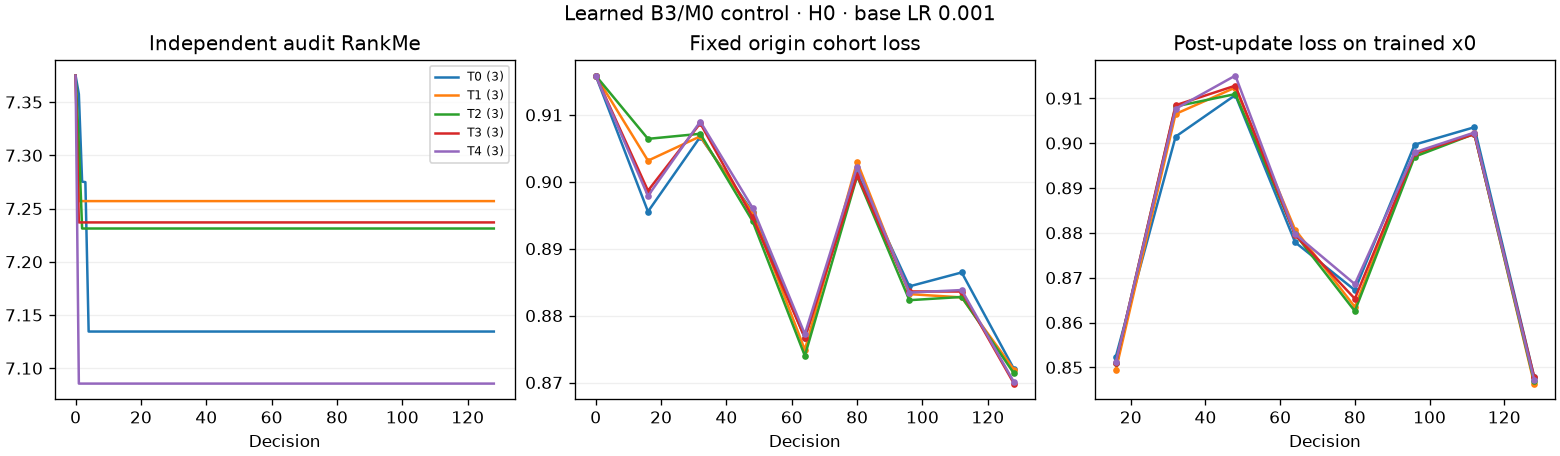

In [ ]:
trajectories_plot(traces,0); plt.show()

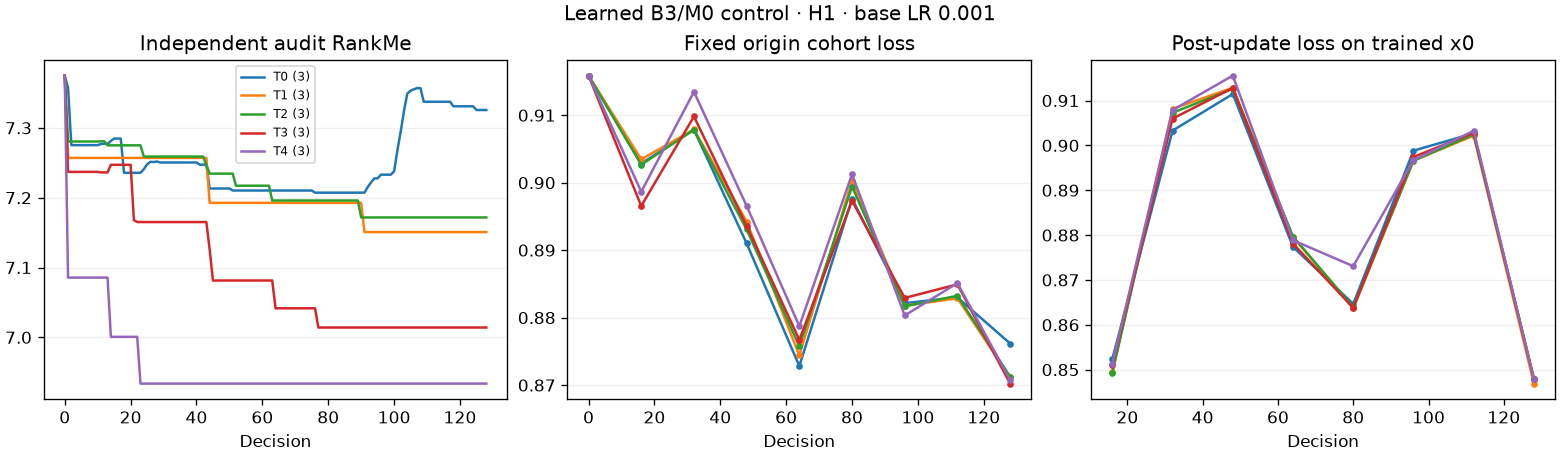

In [ ]:
trajectories_plot(traces,1); plt.show()

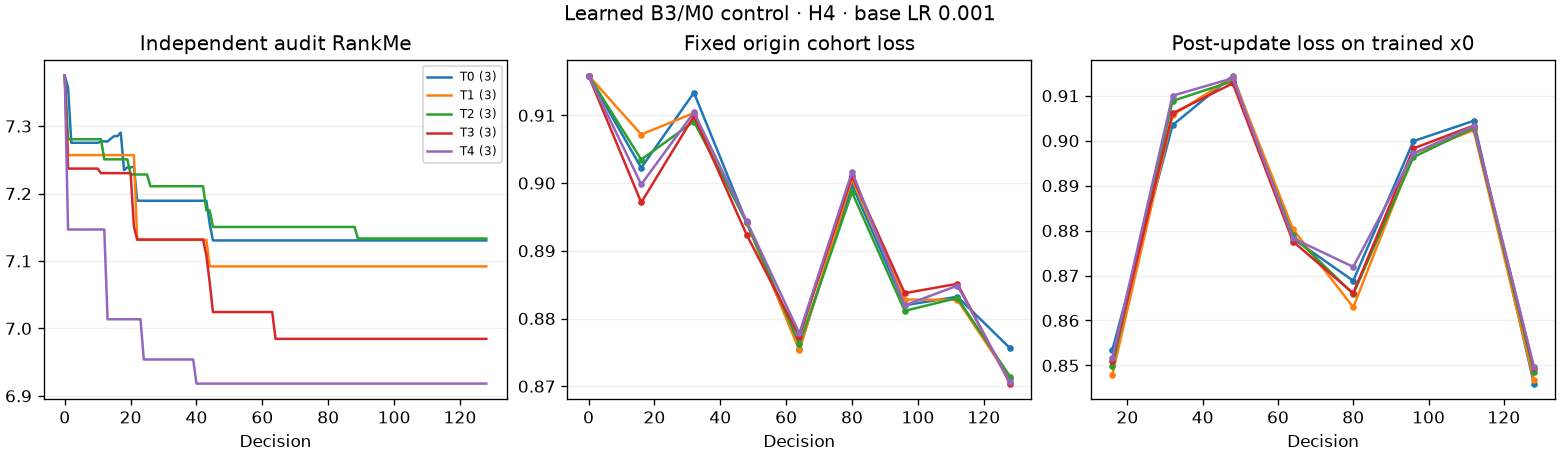

In [ ]:
trajectories_plot(traces,4); plt.show()

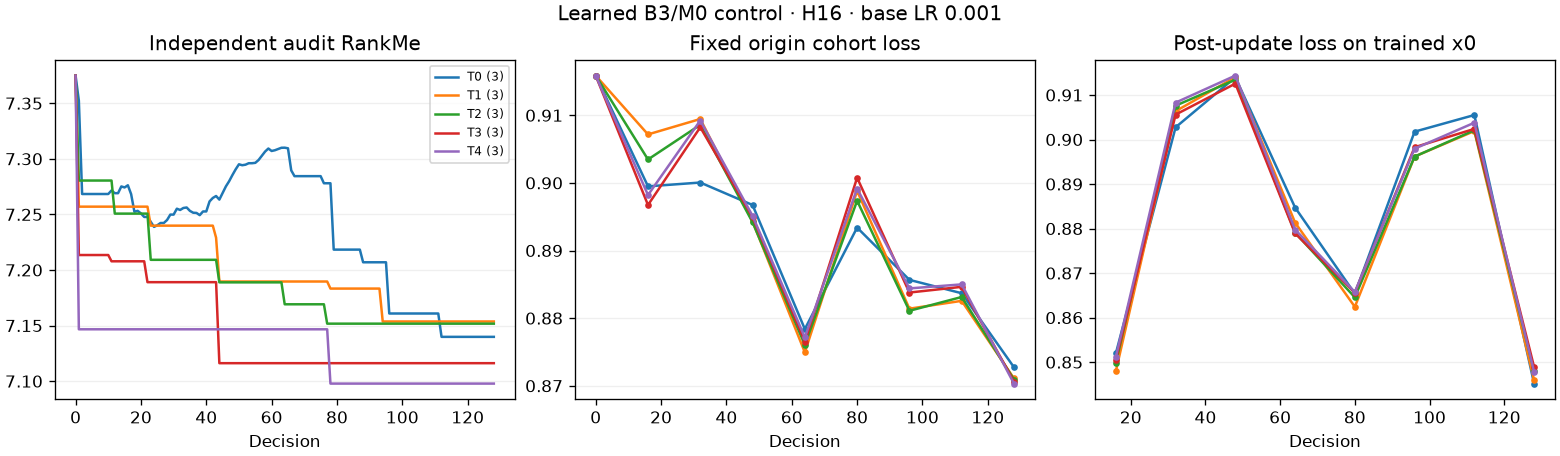

In [ ]:
trajectories_plot(traces,16); plt.show()